# DLM tutorial: CmdStanPy and xarray

This notebook walks through preparing an ozone time series and regressors, fitting the DLM with CmdStanPy, and exploring posterior results with xarray. It uses the vanilla AR1 model and example data included in this repository.

Before running the notebook, follow the CmdStanPy setup in `INSTALL.md` and run `python compile_stan_models.py` from the repository root. The generated `models/dlm_vanilla_ar1.pkl` marker is loaded below; CmdStanPy compiles its Stan source when the model is instantiated.

## Import the required packages

In [34]:
# Import required modules
import arviz as az
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy.stats as stats
import xarray as xr
from cmdstanpy import CmdStanModel
from stan_backend import load_model_object
from utils.utils import prepare_missing_data, sampling_rate
%matplotlib inline

# Load the DLM model

Run `python compile_stan_models.py` from the repository root before loading a model. The generator creates the canonical model marker as well as the backend-specific Stan source. This tutorial uses `dlm_vanilla_ar1`, which includes a nonlinear trend, seasonal cycle, regression coefficients, and an AR1 process. See `models/model_descriptions/` for model details.

In [11]:
# Load the CmdStanPy marker and compile the model if needed
model_marker = load_model_object('models/dlm_vanilla_ar1.pkl')
if not isinstance(model_marker, dict) or model_marker.get('backend') != 'cmdstanpy':
    raise RuntimeError('Expected a CmdStanPy marker; run compile_stan_models.py in the CmdStanPy environment.')
dlm_model = CmdStanModel(stan_file=model_marker['stan_file'])

# Load the example time series

This example uses the BASIC stratospheric ozone composite [Ball et al. 2017](https://www.research-collection.ethz.ch/handle/20.500.11850/202027) and selects one pressure/latitude series. The dataset is opened with xarray so variables can be selected by their named dimensions.

For your own data, prepare `d` as a one-dimensional time series and `s` as its one-dimensional measurement-uncertainty series. Replace missing observations with NaNs, then use `prepare_missing_data(d, s)` to substitute a neutral value and assign the missing observations very large uncertainties.

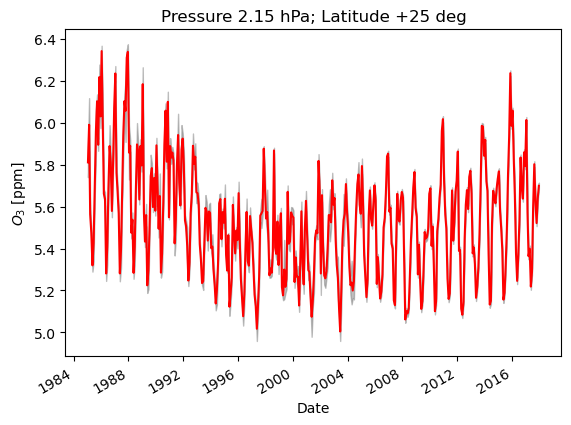

In [12]:
# Open the example dataset and decode its IDL Julian-day coordinate once
source_ds = xr.open_dataset('data/BASIC_V1_2017_lotus_seascyc_gcsw2017_fac2.nc')
source_ds = source_ds.assign_coords(
    time=pd.to_datetime(source_ds['time'].values, unit='D', origin='julian')
)
time = source_ds['time']
P = source_ds['pressure'].to_numpy()
L = source_ds['latitude'].to_numpy()

# Select one pressure and latitude index
pressure = 22
latitude = 8

d = source_ds['o3'].isel(pressure=pressure, latitude=latitude).to_numpy()
s = source_ds['o3_sigma'].isel(pressure=pressure, latitude=latitude).to_numpy()
d, s = prepare_missing_data(d, s)

# Plot the selected time series and uncertainties on calendar dates
plt.title(f'Pressure {P[pressure]:.2f} hPa; Latitude {L[latitude]:+.0f} deg')
plt.plot(time, d, color='red')
plt.fill_between(time, d - s, d + s, color='grey', alpha=0.5)
plt.xlabel('Date')
plt.ylabel(r'$O_3$ [ppm]')
plt.gcf().autofmt_xdate()
plt.show()

## Prepare the regressors

The `regressors/` directory contains example indices for ENSO, solar activity, QBO30, QBO50, and stratospheric aerosol optical depth (SAOD). Both the dataset and regressor files store time as IDL Julian-day values. The data-loading cell decodes the dataset coordinate to calendar timestamps; the next cell decodes each regressor's time column the same way and uses xarray interpolation to align it with `time`.

Regressors must be finite and should be scaled comparably. Normalize them as appropriate for your analysis; missing values are not supported by the Stan model.

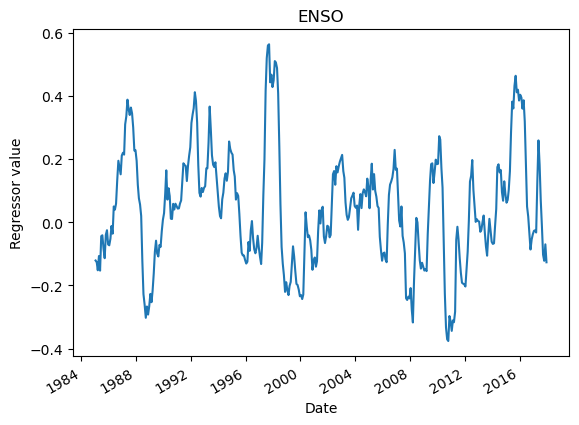

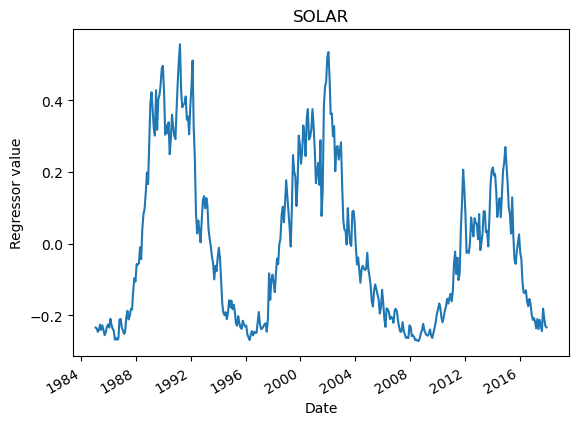

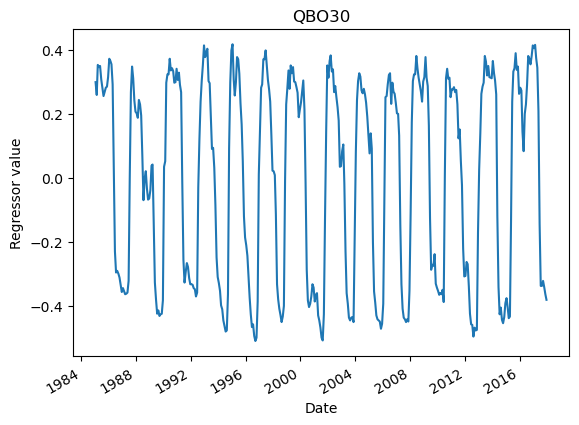

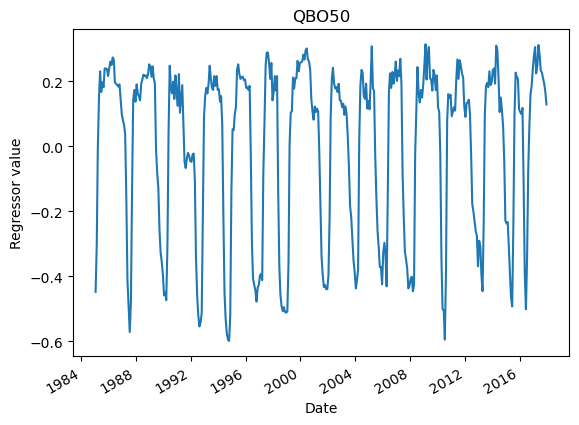

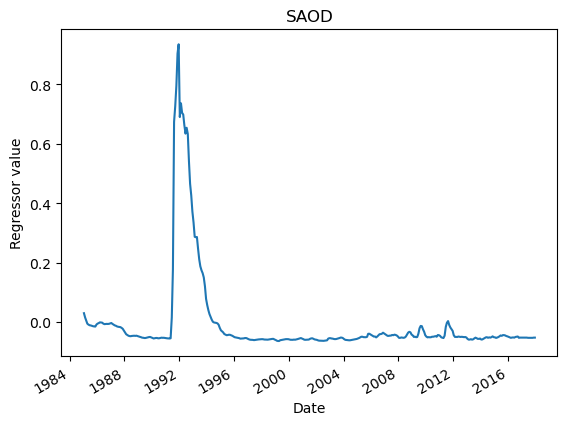

In [13]:
# Decode each IDL Julian time column and interpolate with xarray onto the data dates
def interpolate_regressor(path, column):
    values = np.loadtxt(path)
    regressor_time = pd.to_datetime(values[:, 0], unit='D', origin='julian')
    regressor = xr.DataArray(
        values[:, column],
        coords={'time': regressor_time},
        dims=('time',),
    )
    return regressor.interp(time=time).to_numpy()

enso = interpolate_regressor('regressors/ENSO_MEI_1950_201802.txt', 1)
solar = interpolate_regressor('regressors/Flux_F30_monthly_195111_201803_absolute.txt', 1)
qbo30 = interpolate_regressor('regressors/multi_qbo30_1953_2018.txt', 1)
qbo50 = interpolate_regressor('regressors/multi_qbo50_1953_2018.txt', 1)
saod = interpolate_regressor('regressors/sad_1979_2017_10deg_60S_60N.txt', latitude + 1)

regressor_names = ['ENSO', 'SOLAR', 'QBO30', 'QBO50', 'SAOD']
regressors = np.column_stack([enso, solar, qbo30, qbo50, saod])

for name, values in zip(regressor_names, (enso, solar, qbo30, qbo50, saod)):
    plt.plot(time, values)
    plt.title(name)
    plt.xlabel('Date')
    plt.ylabel('Regressor value')
    plt.gcf().autofmt_xdate()
    plt.show()

## Build the model input

The vanilla AR1 model expects an `input_data` dictionary with:

- `time_series` and `stddev`: length-`N` data and measurement uncertainty vectors.
- `N` and `nreg`: the number of time steps and regressors.
- `regressors`: an `(N, nreg)` array aligned with the observations.
- `sampling`: the time-sampling interval from `sampling_rate()`.
- `S`, `sigma_trend_prior`, `sigma_seas_prior`, and `sigma_AR_prior`: prior settings.

CmdStanPy initializes the sampler automatically by default. No separate `initial_state` dictionary is needed for this model.

In [14]:
# Prepare the dictionary of data and prior settings for the DLM
input_data = {
    'time_series': d,
    'stddev': s,
    'N': len(d),
    'nreg': regressors.shape[1],
    'regressors': regressors,
    'sampling': sampling_rate('monthly'),
    'S': 10.0,
    'sigma_trend_prior': 1e-4,
    'sigma_seas_prior': 0.01,
    'sigma_AR_prior': 0.5,
}

## Sample the DLM with CmdStanPy

`CmdStanModel.sample()` returns a `CmdStanMCMC` object. `iter_sampling` is the number of post-warmup draws **per chain**. Warmup draws from `iter_warmup` are excluded from the posterior by default. With the default thinning of one, the total retained draws across chains are `chains * iter_sampling`; xarray keeps these organized as separate `chain` and `draw` dimensions rather than flattening them.

The example below runs four chains with 1,000 warmup and 2,000 sampling iterations per chain. That yields 2,000 retained draws per chain (8,000 total); the 1,000 warmup draws per chain are excluded. Increase sampling as needed and inspect chain diagnostics before drawing scientific conclusions.

In [ ]:
# Sample the model
chains = 4
warmup = 1000
sampling = 2000
fit = dlm_model.sample(
    data=input_data,
    chains=chains,
    iter_warmup=warmup,
    iter_sampling=sampling,
    show_progress=True,
)but 

14:54:17 - cmdstanpy - INFO - CmdStan start processing
chain 1:   0%|          | 0/3000 [00:00<?, ?it/s, (Warmup)]





chain 1:   3%|▎         | 100/3000 [00:07<03:38, 13.29it/s, (Warmup)]


chain 1:   7%|▋         | 200/3000 [00:11<02:28, 18.91it/s, (Warmup)]


chain 1:  10%|█         | 300/3000 [00:15<02:05, 21.53it/s, (Warmup)]


chain 1:  13%|█▎        | 400/3000 [00:18<01:51, 23.30it/s, (Warmup)]


chain 1:  17%|█▋        | 500/3000 [00:22<01:38, 25.46it/s, (Warmup)]


chain 1:  20%|██        | 600/3000 [00:25<01:25, 28.09it/s, (Warmup)]

chain 1:  23%|██▎       | 700/3000 [00:27<01:15, 30.50it/s, (Warmup)]


chain 1:  27%|██▋       | 800/3000 [00:30<01:06, 32.89it/s, (Warmup)]

chain 1:  30%|███       | 900/3000 [00:32<01:00, 34.87it/s, (Warmup)]


chain 1:  33%|███▎      | 1000/3000 [00:35<00:57, 34.57it/s, (Sampling)]





chain 1:  37%|███▋      | 1100/3000 [00:43<01:25, 22.28it/s, (Sampling)]



chain 1:  40%|████      | 1200/3000 [00:51<01:39, 18.05it/s, (Sampling)]


chain


14:57:52 - cmdstanpy - INFO - CmdStan done processing.
14:57:52 - cmdstanpy - WARNING - Non-fatal error during sampling:
Exception: normal_lpdf: Scale parameter is nan, but must be positive! (in 'dlm_vanilla_ar1_cmdstanpy.stan', line 178, column 8 to column 54)
Exception: normal_lpdf: Scale parameter is nan, but must be positive! (in 'dlm_vanilla_ar1_cmdstanpy.stan', line 178, column 8 to column 54)
Consider re-running with show_console=True if the above output is unclear!


## Inspect the posterior draws

CmdStanPy's `draws_xr()` returns an xarray `Dataset` with separate `chain` and `draw` dimensions. The Stan vectors have model-generated dimensions (for example, `trend_dim_0`); the next cell relabels those as the observation `time` and `regressor` coordinates. Keeping chain and draw separate is useful for diagnostics and posterior summaries.

In [24]:
# Retain chain/draw axes and align posterior values with the native xarray time coordinate
var_names = ['trend', 'slope', 'seasonal', 'beta', 'sigma_trend', 'sigma_seas', 'sigma_AR', 'rhoAR1']
draws = fit.draws_xr(vars=var_names)
posterior = xr.Dataset(
    {
        'trend': (('chain', 'draw', 'time'), draws['trend'].to_numpy()),
        'slope': (('chain', 'draw', 'time'), draws['slope'].to_numpy()),
        'seasonal': (('chain', 'draw', 'time'), draws['seasonal'].to_numpy()),
        'beta': (('chain', 'draw', 'regressor'), draws['beta'].to_numpy()),
        'sigma_trend': (('chain', 'draw'), draws['sigma_trend'].to_numpy()),
        'sigma_seas': (('chain', 'draw'), draws['sigma_seas'].to_numpy()),
        'sigma_AR': (('chain', 'draw'), draws['sigma_AR'].to_numpy()),
        'rhoAR1': (('chain', 'draw'), draws['rhoAR1'].to_numpy()),
    },
    coords={
        'chain': draws['chain'].to_numpy(),
        'draw': draws['draw'].to_numpy(),
        'time': time,
        'regressor': regressor_names,
    },
)

# Flatten chain/draw only for the existing posterior summary plots
trend = posterior['trend'].values.reshape(-1, len(time))
slope = posterior['slope'].values.reshape(-1, len(time))
seasonal_cycle = posterior['seasonal'].values.reshape(-1, len(time))
regressor_coefficients = posterior['beta'].values.reshape(-1, len(regressor_names))
sigma_trend = posterior['sigma_trend'].values.reshape(-1)
sigma_seas = posterior['sigma_seas'].values.reshape(-1)
sigma_AR = posterior['sigma_AR'].values.reshape(-1)
rhoAR1 = posterior['rhoAR1'].values.reshape(-1)

## Finally, let's make some plots of the outputs!

**Obviously we can compute and plot whatever we like now we have the results, but let's make a few example plots of the various parameters we have inferred to showcase the results.**

### Let's start by plotting the recovered dlm trend and corresponding (1$\sigma$) uncertainties:

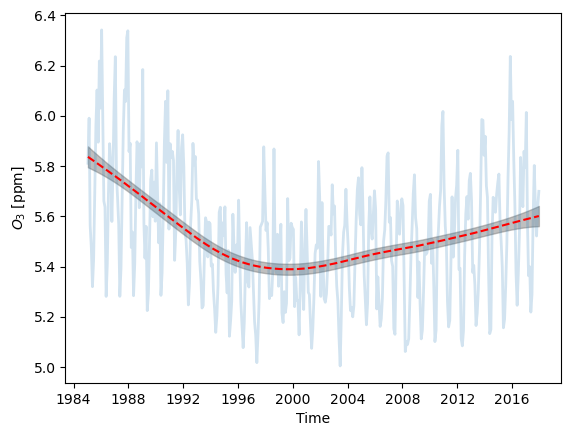

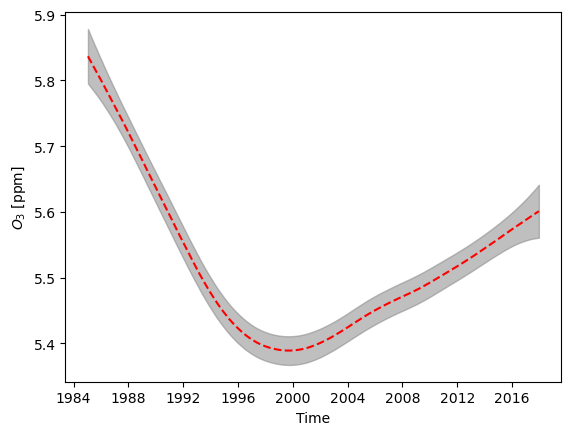

In [25]:
# Plot posterior trend summaries against the data
trend_mean = np.mean(trend, axis=0)
trend_std = np.std(trend, axis=0)

plt.plot(time, d, lw=2, alpha=0.2)
plt.plot(time, trend_mean, color='red', ls='--')
plt.fill_between(time, trend_mean - trend_std, trend_mean + trend_std, color='grey', alpha=0.5)
plt.xlabel('Time')
plt.ylabel(r'$O_3$ [ppm]')
plt.show()

# Same plot without the observations for a closer look at the trend
plt.plot(time, trend_mean, color='red', ls='--')
plt.fill_between(time, trend_mean - trend_std, trend_mean + trend_std, color='grey', alpha=0.5)
plt.xlabel('Time')
plt.ylabel(r'$O_3$ [ppm]')
plt.show()

### We can also plot the recovered slope of the trend as a function of time (negative slope indicates ozone depletion, positive slope indicates recovery):

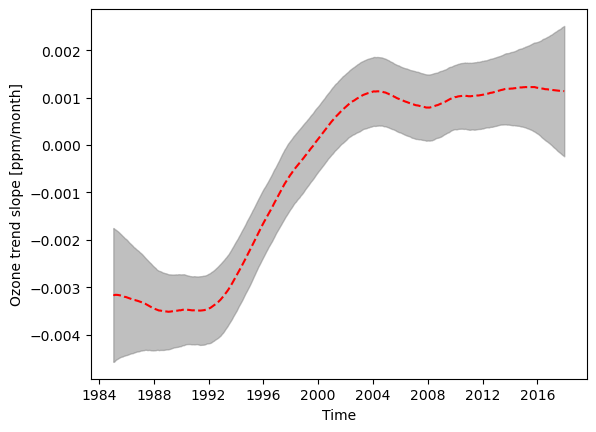

In [26]:
# Plot the posterior slope of the recovered trend
slope_mean = np.mean(slope, axis=0)
slope_std = np.std(slope, axis=0)
plt.plot(time, slope_mean, color='red', ls='--')
plt.fill_between(time, slope_mean - slope_std, slope_mean + slope_std, color='grey', alpha=0.5)
plt.xlabel('Time')
plt.ylabel('Ozone trend slope [ppm/month]')
plt.show()

### Now for the recovered seasonal cycle - note that modulation in the amplitude of the seasonal cycle is allowed in the dlm model (and here is preferred by the data):

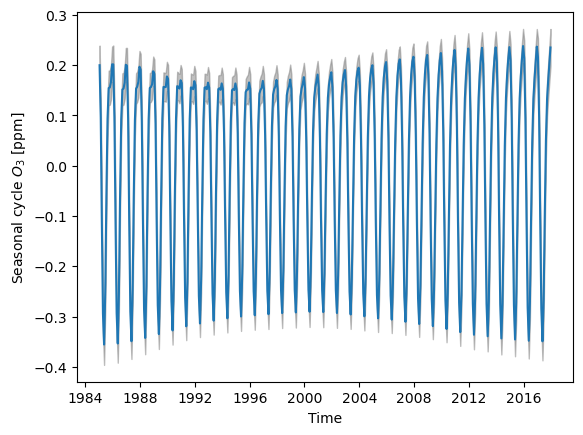

In [27]:
# Plot the posterior seasonal cycle and uncertainty
seasonal_mean = np.mean(seasonal_cycle, axis=0)
seasonal_std = np.std(seasonal_cycle, axis=0)
plt.plot(time, seasonal_mean)
plt.fill_between(time, seasonal_mean - seasonal_std, seasonal_mean + seasonal_std, color='grey', alpha=0.5)
plt.xlabel('Time')
plt.ylabel('Seasonal cycle $O_3$ [ppm]')
plt.show()

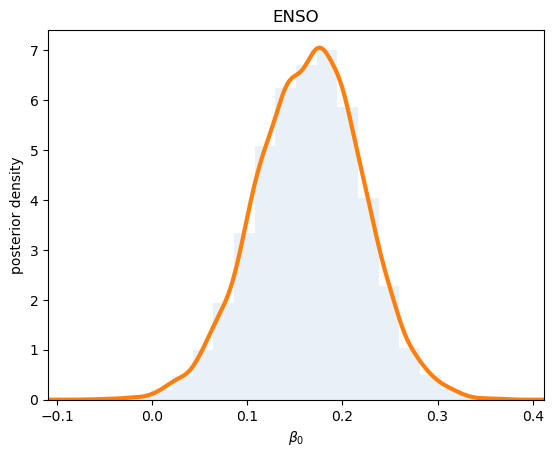

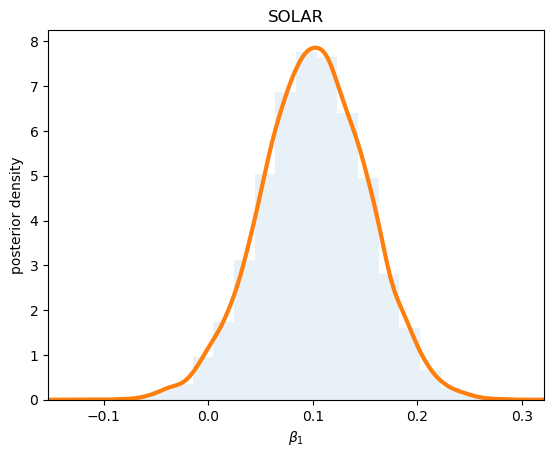

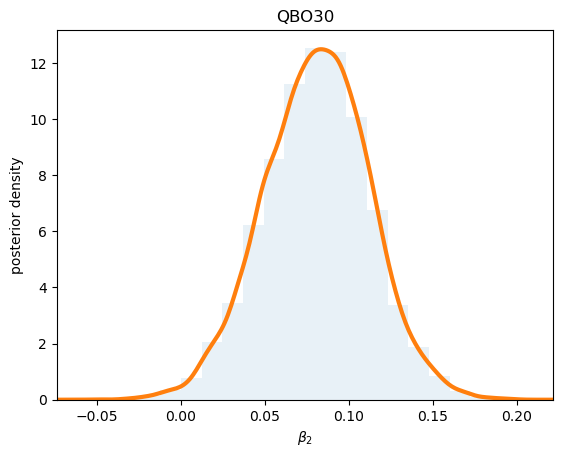

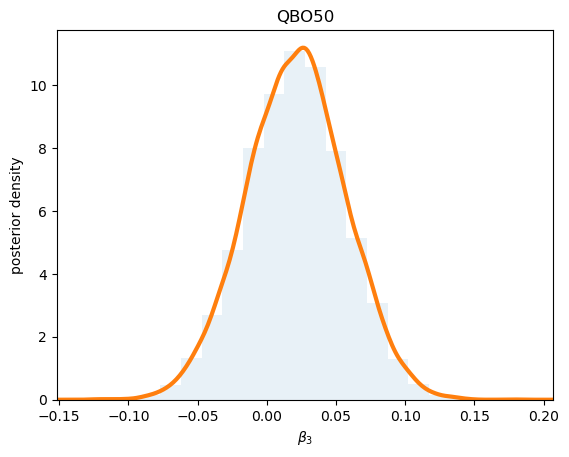

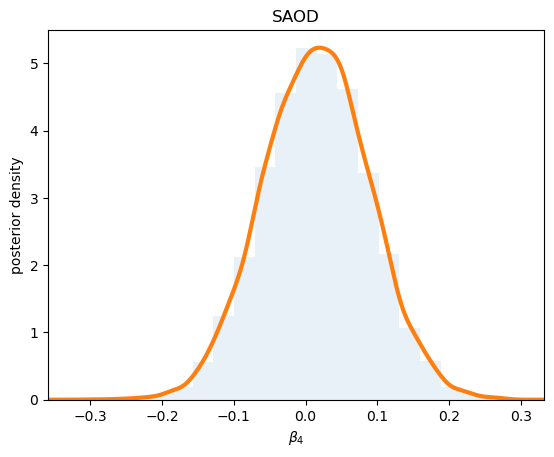

In [28]:
# Plot posteriors for the regression coefficients
regressor_names = ['ENSO', 'SOLAR', 'QBO30', 'QBO50', 'SAOD']
for i in range(len(regressors.T)):
    beta = regressor_coefficients[:,i]
    kde = stats.gaussian_kde(beta)
    x = np.linspace(min(beta) - np.ptp(beta)*0.1, max(beta) + np.ptp(beta)*0.1, 300)
    plt.hist(beta, bins=20, density=True, alpha = 0.1)
    plt.plot(x, kde(x), lw = 3)
    plt.xlim(x[0], x[-1])
    plt.title(regressor_names[i])
    plt.ylabel('posterior density')
    plt.xlabel(r'$\beta_{}$'.format(i))
    plt.show()

### We can also plot histograms of the dlm hyper-parameter posteriors:

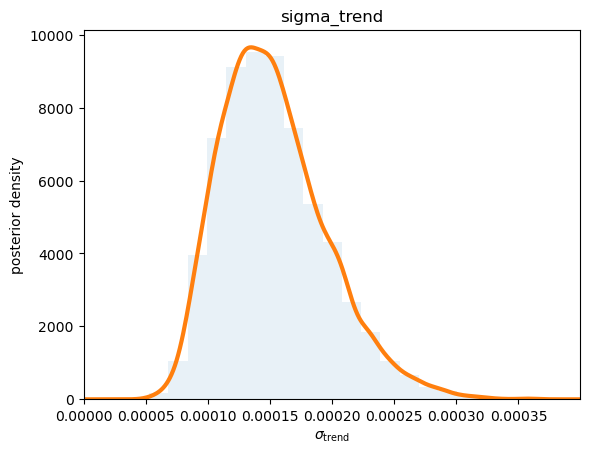

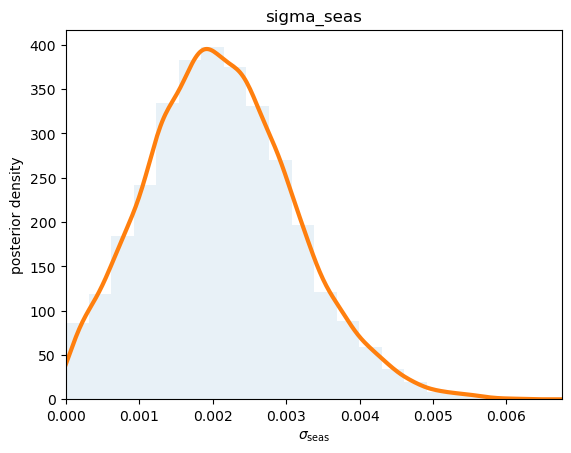

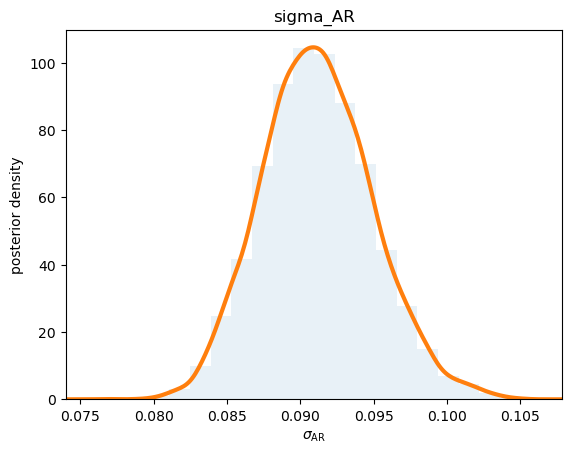

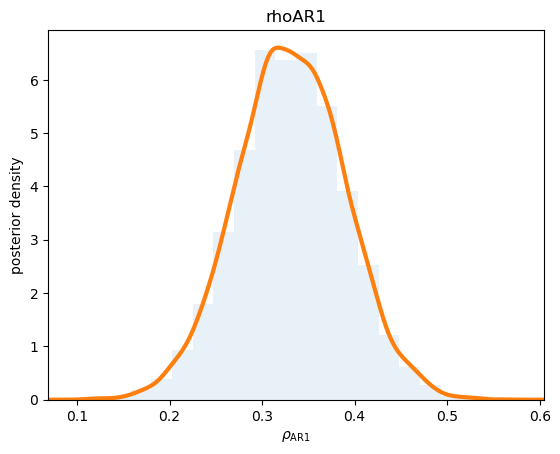

In [30]:
# Plot posteriors for the DLM hyper parameters
kde = stats.gaussian_kde(sigma_trend)
x = np.linspace(0, max(sigma_trend)*1.1, 300)
plt.hist(sigma_trend, bins=20, density=True, alpha = 0.1)
plt.plot(x, kde(x), lw = 3)
plt.xlim(x[0], x[-1])
plt.title('sigma_trend')
plt.ylabel('posterior density')
plt.xlabel(r'$\sigma_\mathrm{trend}$')
plt.show()

kde = stats.gaussian_kde(sigma_seas)
x = np.linspace(0, max(sigma_seas)*1.1, 300)
plt.hist(sigma_seas, bins=20, density=True, alpha = 0.1)
plt.plot(x, kde(x), lw = 3)
plt.xlim(x[0], x[-1])
plt.title('sigma_seas')
plt.ylabel('posterior density')
plt.xlabel(r'$\sigma_\mathrm{seas}$')
plt.show()

kde = stats.gaussian_kde(sigma_AR)
x = np.linspace(min(sigma_AR) - np.ptp(sigma_AR)*0.1, max(sigma_AR) + np.ptp(sigma_AR)*0.1, 300)
plt.hist(sigma_AR, bins=20, density=True, alpha = 0.1)
plt.plot(x, kde(x), lw = 3)
plt.xlim(x[0], x[-1])
plt.title('sigma_AR')
plt.ylabel('posterior density')
plt.xlabel(r'$\sigma_\mathrm{AR}$')
plt.show()

kde = stats.gaussian_kde(rhoAR1)
x = np.linspace(min(rhoAR1) - np.ptp(rhoAR1)*0.1, max(rhoAR1) + np.ptp(rhoAR1)*0.1, 300)
plt.hist(rhoAR1, bins=20, density=True, alpha = 0.1)
plt.plot(x, kde(x), lw = 3)
plt.xlim(x[0], x[-1])
plt.title('rhoAR1')
plt.ylabel('posterior density')
plt.xlabel(r'$\rho_\mathrm{AR1}$')
plt.show()

### Check the sampler traces

Trace plots show draws by chain and can reveal poor mixing or trends. They are one diagnostic, not proof of convergence. If chains mix poorly, investigate the model and data and run longer chains; also review CmdStan's summary diagnostics such as R-hat and effective sample size.

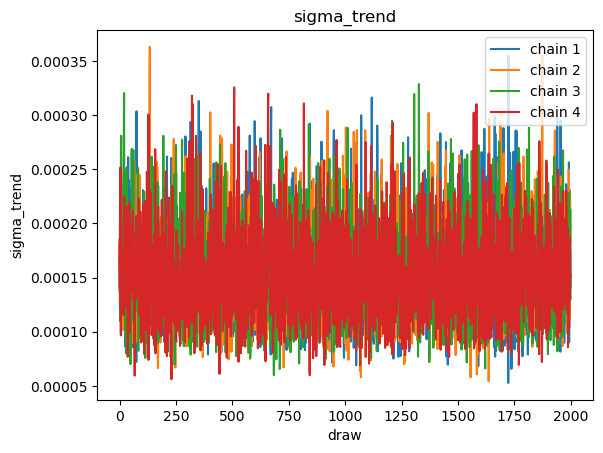

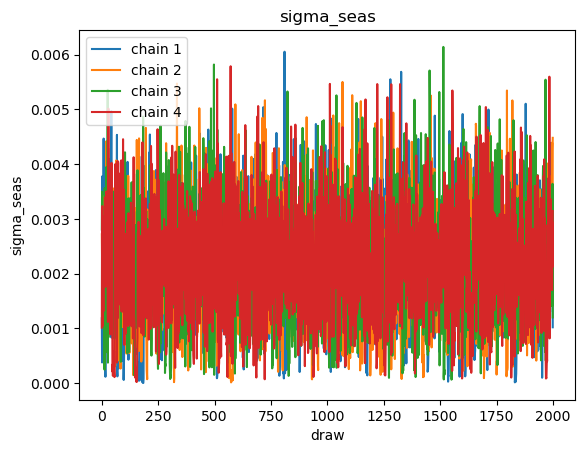

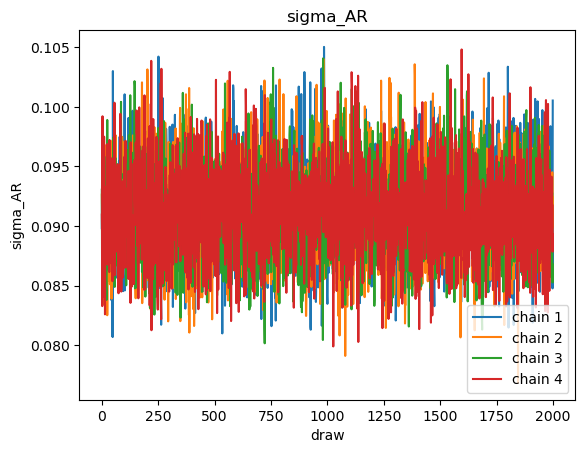

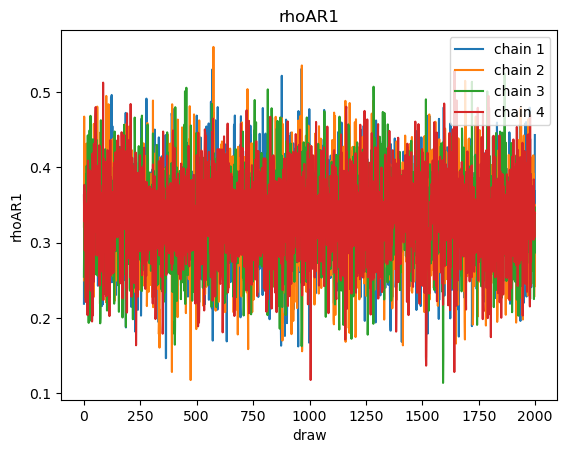

In [31]:
# Plot each chain separately for the model hyperparameters
for name in ('sigma_trend', 'sigma_seas', 'sigma_AR', 'rhoAR1'):
    for chain in posterior['chain'].values:
        values = posterior[name].sel(chain=chain)
        plt.plot(posterior['draw'].values, values.values, label=f'chain {chain}')
    plt.title(name)
    plt.xlabel('draw')
    plt.ylabel(name)
    plt.legend()
    plt.show()

### Summarize convergence diagnostics

Compare chains using R-hat and effective sample size for parameters that matter to your analysis. R-hat values near 1 (commonly below 1.01) and adequate bulk/tail ESS are reassuring, but no single threshold proves convergence. Also check for divergent transitions; any divergences can indicate difficult posterior geometry and should be investigated.

In [36]:
# Summarize only scalar hyperparameters instead of all generated quantities
diagnostic_parameters = ['sigma_trend', 'sigma_seas', 'sigma_AR', 'rhoAR1']
diagnostic_draws = fit.draws_xr(vars=diagnostic_parameters)
diagnostic_data = az.from_dict(
    data={
        'posterior': {
            name: diagnostic_draws[name].transpose('chain', 'draw').to_numpy()
            for name in diagnostic_parameters
        }
    },
    sample_dims=['chain', 'draw'],
    coords={
        'chain': diagnostic_draws['chain'].to_numpy(),
        'draw': diagnostic_draws['draw'].to_numpy(),
    },
)
display(az.summary(diagnostic_data, var_names=diagnostic_parameters, kind='all', round_to=3))

sampler_diagnostics = fit.method_variables()
divergences = sampler_diagnostics.get('divergent__')
if divergences is None:
    print('Divergence count is unavailable in this CmdStan output.')
else:
    print(f'Divergent transitions: {int(np.asarray(divergences).sum())}')

,mean,sd,eti89_lb,eti89_ub,ess_bulk,ess_tail,r_hat,mcse_mean,mcse_sd
sigma_trend,0.000,0.000,0.000,0.000,7375.957,5631.266,1.001,0.000,0.000
sigma_seas,0.002,0.001,0.001,0.004,4424.357,2753.538,1.000,0.000,0.000
sigma_AR,0.091,0.004,0.085,0.097,6773.319,5543.528,1.000,0.000,0.000
rhoAR1,0.331,0.058,0.238,0.423,7370.166,4646.492,1.001,0.001,0.001


Divergent transitions: 0


### Finally, we can do things like plot the posterior for the net background change in ozone between two key dates (here, January 1998 and December 2017)

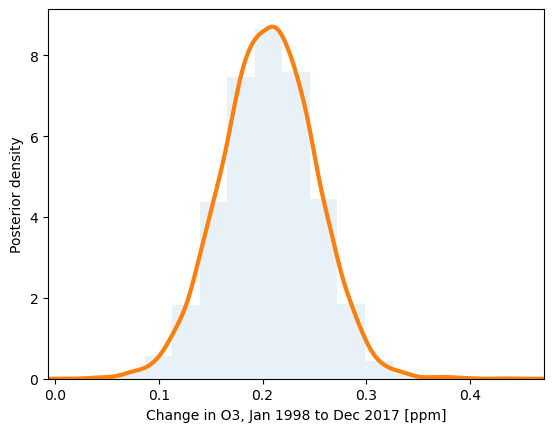

In [32]:
# Compare the trend at January 1998 and December 2017
jan1998 = 156
dec2017 = -1
delta_o3 = trend[:, dec2017] - trend[:, jan1998]

kde = stats.gaussian_kde(delta_o3)
x = np.linspace(delta_o3.min() - np.ptp(delta_o3) * 0.1, delta_o3.max() + np.ptp(delta_o3) * 0.1, 300)
plt.hist(delta_o3, bins=15, alpha=0.1, density=True)
plt.plot(x, kde(x), lw=3)
plt.xlim(x[0], x[-1])
plt.xlabel('Change in O3, Jan 1998 to Dec 2017 [ppm]')
plt.ylabel('Posterior density')
plt.show()

source_ds.close()

## Congratulations, you made it to the end of the tutorial! 

## By now you should get the idea and, I hope, be able to use this notebook as a template for performing dlm regression on your own data. Good luck and happy DLMing!